In [79]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, metrics
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.utils import class_weight
import numpy as np
import os

# --- KONFIGURASI ---
DATA_DIR = "Dataset_DR_Clean/" # Gunakan folder HASIL PROSES tadi
IMG_SIZE = 300
BATCH_SIZE = 32
EPOCHS_HEAD = 20    # Epoch untuk training head
EPOCHS_FINE = 20    # Epoch untuk fine tuning
NUM_CLASSES = 5
AUTOTUNE=tf.data.AUTOTUNE

In [80]:
import tensorflow as tf
import numpy as np
import pandas as pd
import os
from sklearn.model_selection import train_test_split
from glob import glob

# ==========================================
# 1. SETUP PATH & SPLITTING (Stratified)
# ==========================================
print("Menyiapkan file paths...")

# Ambil semua file path dan labelnya
file_paths = []
labels = []
CLASSES = sorted(os.listdir(DATA_DIR)) # Pastikan urutan folder 0,1,2,3,4

for label_name in CLASSES:
    class_dir = os.path.join(DATA_DIR, label_name)
    if os.path.isdir(class_dir):
        files = glob(os.path.join(class_dir, "*"))
        file_paths.extend(files)
        # Anggap nama folder adalah label (0,1,2,3,4)
        labels.extend([int(label_name)] * len(files))

# Ubah ke numpy array agar mudah displit
file_paths = np.array(file_paths)
labels = np.array(labels)

# A. Split Train (70%) vs Sisa (30%) - STRATIFIED (Wajib agar kelas 4 merata)
train_paths, rest_paths, train_labels, rest_labels = train_test_split(
    file_paths, labels, test_size=0.3, stratify=labels, random_state=123
)

# B. Split Val (15%) vs Test (15%) dari sisa
val_paths, test_paths, val_labels, test_labels = train_test_split(
    rest_paths, rest_labels, test_size=0.5, stratify=rest_labels, random_state=123
)

print(f"Jumlah Training: {len(train_paths)}")
print(f"Jumlah Validasi: {len(val_paths)}")
print(f"Jumlah Testing : {len(test_paths)}")

# ==========================================
# 2. FUNGSI LOAD IMAGE
# ==========================================
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    
    # PENTING: EfficientNet butuh preprocessing tertentu?
    # Jika pakai pre-trained weights ImageNet, gunakan:
    # img = tf.keras.applications.efficientnet.preprocess_input(img) 
    # Jika tidak, normalisasi biasa:
    
    label = tf.one_hot(label, depth=5) # Ubah ke One-Hot Encoding
    return img, label

# ==========================================
# 3. MEMBUAT DATASET (Oversampling Training)
# ==========================================
print("Membangun Balanced Dataset...")

# --- A. DATASET TRAINING (DENGAN OVERSAMPLING) ---
# Kita buat dataset terpisah per kelas, lalu gabung secara merata
train_ds_per_class = []

# Buat dataset tf.data dari paths training
full_train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
full_train_ds = full_train_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

for i in range(5):
    # Filter dataset hanya untuk kelas i
    # (Kita filter dari dataset yang sudah diload path-nya tadi)
    class_ds = full_train_ds.filter(lambda img, label: tf.argmax(label) == i)
    class_ds = class_ds.repeat() # Ulangi terus menerus (Infinite)
    train_ds_per_class.append(class_ds)

# GABUNGKAN DENGAN PELUANG SAMA (20% tiap kelas)
# Ini inti dari Oversampling di tf.data
balanced_train_ds = tf.data.Dataset.sample_from_datasets(
    train_ds_per_class, 
    weights=[0.2, 0.2, 0.2, 0.2, 0.2] # Memaksa rasio 1:1:1:1:1
)

# Batching & Prefetching Training
# Perlu tentukan 'steps_per_epoch' nanti di model.fit karena ini infinite dataset
train_ds = balanced_train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


# --- B. DATASET VALIDASI & TEST (NORMAL/TANPA OVERSAMPLING) ---
val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_ds = val_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_ds = test_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Dataset Siap!")

Menyiapkan file paths...
Jumlah Training: 24575
Jumlah Validasi: 5266
Jumlah Testing : 5267
Membangun Balanced Dataset...
Dataset Siap!


In [81]:
import numpy as np
import matplotlib.pyplot as plt
# for img, label in train_ds.take(1):
#     plt.imshow(img[2].numpy().astype('uint8'))

    # Cek batch pertama dari generator/dataset Anda
images, labels = next(iter(train_ds)) 

print("Min Value:", np.min(images))
print("Max Value:", np.max(images))
print("Shape:", images.shape)

Min Value: 0.0
Max Value: 255.0
Shape: (32, 300, 300, 3)


In [82]:
# ==========================================
# 3. MEMBANGUN MODEL (EfficientNetB3)
# ==========================================
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    
x=tf.keras.Sequential([
    layers.RandomRotation(0.2),
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomContrast(0.15),
    layers.RandomZoom(height_factor=(-0.1, -0.1), width_factor=(-0.1, -0.1)), # Zoom in dikit
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
], name='retina_augmentation')(inputs)
    
# Backbone: EfficientNetB3
# include_top=False membuang layer klasifikasi bawaan
base_model = tf.keras.applications.EfficientNetB3(
    include_top=False, 
    weights="imagenet", 
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
    
# Freeze backbone dulu
base_model.trainable = False
x = base_model(x, training=False)
# Head Baru
avg_pool = layers.GlobalAveragePooling2D()(x)
max_pool = layers.GlobalMaxPooling2D()(x)
x = layers.Concatenate()([avg_pool, max_pool])
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.5)(x) # Drop 50% neuron biar tidak menghafal
x = layers.Dense(512, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(5, dtype='float32',activation='softmax')(x)
    
model = models.Model(inputs, outputs)



In [ ]:
checkpoint = ModelCheckpoint("best_model_dr_phase1.keras", monitor='val_auc', save_best_only=True, mode='max', verbose=1)
early_stop = EarlyStopping(monitor='val_auc', patience=5, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1)

checkpoint_ft = tf.keras.callbacks.ModelCheckpoint(
    "best_model_dr_final.keras", # File final
    monitor='val_auc', 
    save_best_only=True, 
    mode='max',
    verbose=1
)
early_stop_ft = tf.keras.callbacks.EarlyStopping(
    monitor='val_auc', 
    patience=10, # Sabar sedikit di fase fine tuning
    restore_best_weights=True,
    verbose=1
)

steps_per_epoch = len(train_paths) // BATCH_SIZE 
val_steps = len(val_paths) // BATCH_SIZE

METRICS = [
    metrics.CategoricalAccuracy(name='accuracy'),
    metrics.AUC(name='auc'),
    metrics.Recall(name='recall') # Fokus agar tidak ada False Negative
]

In [84]:
# ==========================================
# 4. TRAINING FASE 1 (HEAD ONLY)
# ==========================================

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=METRICS
)


print("\n--- MULAI TRAINING FASE 1 (Head Only) ---")

hhistory_1 = model.fit(
    train_ds,
    epochs=15, # Biasanya 10-15 epoch cukup utk head
    validation_data=val_ds,
    steps_per_epoch=steps_per_epoch, # <--- KRUSIAL!
    validation_steps=val_steps,      # <--- Opsional tapi bagus
    callbacks=[checkpoint, reduce_lr, early_stop]
)



--- MULAI TRAINING FASE 1 (Head Only) ---
Epoch 1/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step - accuracy: 0.3396 - auc: 0.6605 - loss: 2.5136 - recall: 0.2863
Epoch 1: val_auc improved from None to 0.85336, saving model to best_model_dr_phase1.keras
767/767 ━━━━━━━━━━━━━━━━━━━━ 274s 306ms/step - accuracy: 0.3671 - auc: 0.6917 - loss: 1.9338 - recall: 0.2608 - val_accuracy: 0.6319 - val_auc: 0.8534 - val_loss: 1.0898 - val_recall: 0.4059 - learning_rate: 0.0010
Epoch 2/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step - accuracy: 0.3995 - auc: 0.7476 - loss: 1.3636 - recall: 0.2032
Epoch 2: val_auc did not improve from 0.85336
767/767 ━━━━━━━━━━━━━━━━━━━━ 223s 291ms/step - accuracy: 0.4015 - auc: 0.7522 - loss: 1.3496 - recall: 0.2033 - val_accuracy: 0.6042 - val_auc: 0.8409 - val_loss: 1.1340 - val_recall: 0.2487 - learning_rate: 0.0010
Epoch 3/15
767/767 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step - accuracy: 0.4126 - auc: 0.7572 - loss: 1.3364 - recall: 0.2061
Epoch 3: val_auc did not improve 

In [85]:
# ==========================================
# 5. TRAINING FASE 2 (FINE TUNING)
# ==========================================
print("\n--- MULAI TRAINING FASE 2 (Fine Tuning) ---")

# Unfreeze backbone
base_model.trainable = True

# Freeze layer awal (biar fitur dasar tidak rusak), unfreeze layer akhir
# EfficientNetB3 punya sekitar 380+ layer
for layer in base_model.layers[:-50]: # Freeze semua kecuali 50 layer terakhir
    layer.trainable = False

# Compile ulang dengan LR SANGAT KECIL
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5), # 1/100 dari sebelumnya
    loss='categorical_crossentropy',
    metrics=METRICS
)

history_2 = model.fit(
    train_ds,
    epochs=30, # Beri waktu lebih lama utk fine tuning
    validation_data=val_ds,
    steps_per_epoch=steps_per_epoch, # <--- KRUSIAL!
    validation_steps=val_steps,
    callbacks=[checkpoint_ft, early_stop_ft, reduce_lr]
)

print("Training Selesai. Model terbaik tersimpan sebagai 'best_model_dr_final.keras'")


--- MULAI TRAINING FASE 2 (Fine Tuning) ---
Epoch 1/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 0s 300ms/step - accuracy: 0.4234 - auc: 0.7584 - loss: 1.4415 - recall: 0.1329
Epoch 1: val_auc improved from None to 0.85751, saving model to best_model_dr_final.keras
767/767 ━━━━━━━━━━━━━━━━━━━━ 318s 353ms/step - accuracy: 0.4057 - auc: 0.7481 - loss: 1.3916 - recall: 0.1458 - val_accuracy: 0.5837 - val_auc: 0.8575 - val_loss: 1.0660 - val_recall: 0.2971 - learning_rate: 1.0000e-05
Epoch 2/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 0s 316ms/step - accuracy: 0.4147 - auc: 0.7639 - loss: 1.3081 - recall: 0.1842
Epoch 2: val_auc improved from 0.85751 to 0.86628, saving model to best_model_dr_final.keras
767/767 ━━━━━━━━━━━━━━━━━━━━ 277s 361ms/step - accuracy: 0.4240 - auc: 0.7719 - loss: 1.2881 - recall: 0.1931 - val_accuracy: 0.6128 - val_auc: 0.8663 - val_loss: 1.0437 - val_recall: 0.3312 - learning_rate: 1.0000e-05
Epoch 3/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step - accuracy: 0.4436 - auc: 0.7843 - loss: 1

In [86]:
print("\n🔍 Evaluasi pada TEST SET:")
model.evaluate(test_ds, verbose=1)



🔍 Evaluasi pada TEST SET:
165/165 ━━━━━━━━━━━━━━━━━━━━ 29s 172ms/step - accuracy: 0.6778 - auc: 0.8913 - loss: 0.9571 - recall: 0.4448


[0.9571384191513062,
 0.6778051853179932,
 0.8913354277610779,
 0.4448452591896057]

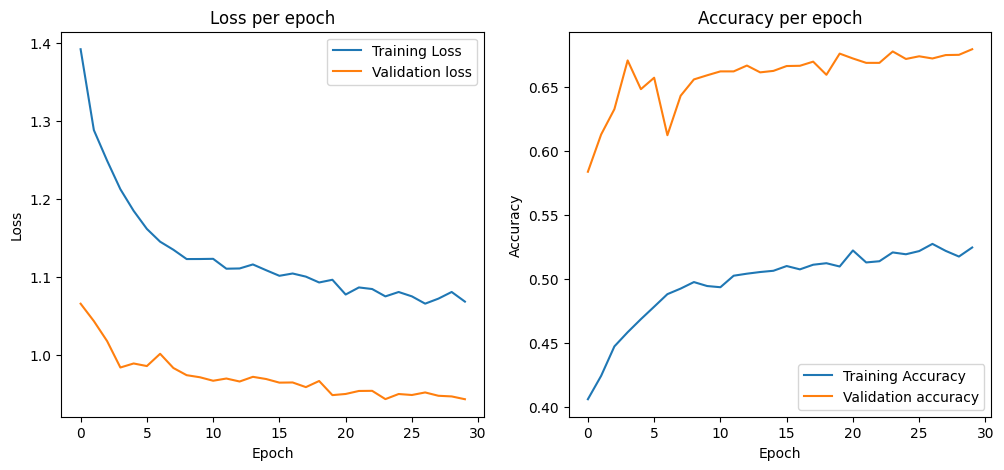

In [87]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_2.history['loss'], label='Training Loss')
plt.plot(history_2.history['val_loss'],
         label='Validation loss')
plt.title('Loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()


plt.subplot(1,2,2)
plt.plot(history_2.history['accuracy'], label='Training Accuracy')
plt.plot(history_2.history['val_accuracy'],
         label='Validation accuracy')
plt.title('Accuracy per epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

In [88]:
# Prediksi data validasi
y_pred = model.predict(val_ds)
y_pred_classes = np.argmax(y_pred, axis=1)

# Ambil label asli (agak tricky kalau pakai tf.data tanpa loop)
y_true = np.concatenate([y for x, y in val_ds], axis=0)
y_true = np.argmax(y_true, axis=1)

from sklearn.metrics import classification_report, confusion_matrix
print(confusion_matrix(y_true, y_pred_classes))
print(classification_report(y_true, y_pred_classes))

165/165 ━━━━━━━━━━━━━━━━━━━━ 40s 220ms/step
[[3240  354  166   36   74]
 [ 299   44   14    4    5]
 [ 384  107  157   92   53]
 [  21    6   22   68   14]
 [   7    1   10   20   68]]
              precision    recall  f1-score   support

           0       0.82      0.84      0.83      3870
           1       0.09      0.12      0.10       366
           2       0.43      0.20      0.27       793
           3       0.31      0.52      0.39       131
           4       0.32      0.64      0.42       106

    accuracy                           0.68      5266
   macro avg       0.39      0.46      0.40      5266
weighted avg       0.69      0.68      0.67      5266



2025-12-11 17:22:49.813587: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [90]:
# Load model yang sudah dilatih sebagian
model = tf.keras.models.load_model("attempt3/best_model_dr_final.keras")

# Compile ulang (PENTING: Reset optimizer state dengan LR kecil)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), # Tetap kecil
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Recall(name='recall'), tf.keras.metrics.AUC(name='auc')]
)

# Lanjut training 20-30 epoch lagi
history_extended = model.fit(
    train_ds,
    epochs=20, # Tambah epoch
    validation_data=val_ds,
    steps_per_epoch=steps_per_epoch,
    validation_steps=val_steps,
    callbacks=[checkpoint_ft, early_stop_ft, reduce_lr]
)

Epoch 1/20
767/767 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step - accuracy: 0.5241 - auc: 0.8456 - loss: 1.0697 - recall: 0.3017
Epoch 1: val_auc improved from 0.89290 to 0.89476, saving model to best_model_dr_final.keras
767/767 ━━━━━━━━━━━━━━━━━━━━ 339s 372ms/step - accuracy: 0.5227 - auc: 0.8452 - loss: 1.0707 - recall: 0.3023 - val_accuracy: 0.6841 - val_auc: 0.8948 - val_loss: 0.9387 - val_recall: 0.4606 - learning_rate: 1.0000e-05
Epoch 2/20
767/767 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step - accuracy: 0.5295 - auc: 0.8505 - loss: 1.0534 - recall: 0.3034
Epoch 2: val_auc improved from 0.89476 to 0.89644, saving model to best_model_dr_final.keras
767/767 ━━━━━━━━━━━━━━━━━━━━ 289s 376ms/step - accuracy: 0.5294 - auc: 0.8498 - loss: 1.0554 - recall: 0.3048 - val_accuracy: 0.6886 - val_auc: 0.8964 - val_loss: 0.9285 - val_recall: 0.4954 - learning_rate: 1.0000e-05
Epoch 3/20
767/767 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/step - accuracy: 0.5322 - auc: 0.8525 - loss: 1.0491 - recall: 0.3130
Epoch 3: val_auc im

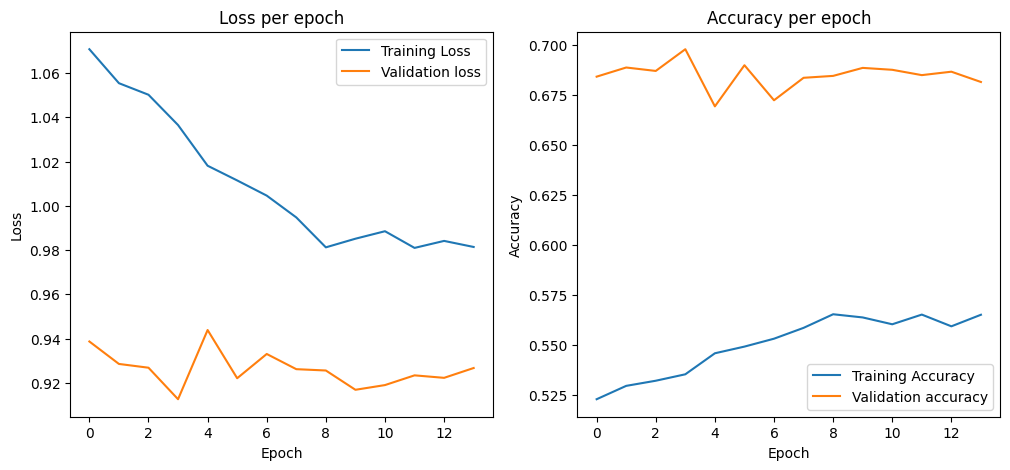

In [91]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_extended.history['loss'], label='Training Loss')
plt.plot(history_extended.history['val_loss'],
         label='Validation loss')
plt.title('Loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()


plt.subplot(1,2,2)
plt.plot(history_extended.history['accuracy'], label='Training Accuracy')
plt.plot(history_extended.history['val_accuracy'],
         label='Validation accuracy')
plt.title('Accuracy per epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

In [92]:
print("Mengevaluasi model pada Data Test...")
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]:.4f}")
print(f"Test Accuracy: {results[1]:.4f}")
print(f"Test AUC: {results[2]:.4f}")
print(f"Test Recall: {results[3]:.4f}")

Mengevaluasi model pada Data Test...
165/165 ━━━━━━━━━━━━━━━━━━━━ 39s 231ms/step - accuracy: 0.6941 - auc: 0.8989 - loss: 0.9243 - recall: 0.4830
Test Loss: 0.9243
Test Accuracy: 0.6941
Test AUC: 0.4830
Test Recall: 0.8989


Sedang memprediksi data test...

--- CLASSIFICATION REPORT ---
               precision    recall  f1-score   support

        No DR       0.82      0.85      0.84      3871
         Mild       0.12      0.14      0.13       365
     Moderate       0.42      0.21      0.28       794
       Severe       0.28      0.48      0.35       131
Proliferative       0.32      0.60      0.42       106

     accuracy                           0.69      5267
    macro avg       0.39      0.46      0.40      5267
 weighted avg       0.69      0.69      0.69      5267



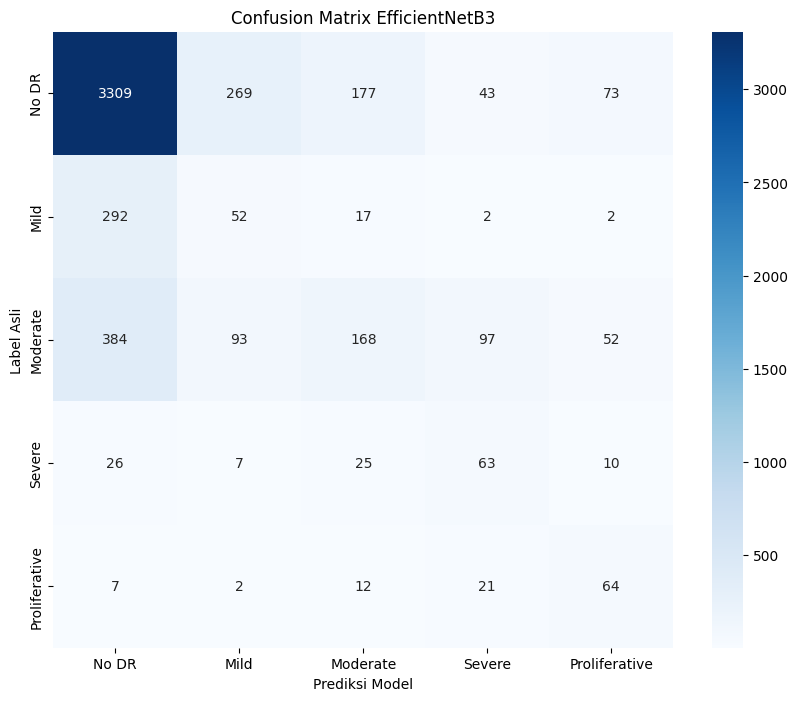

In [95]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Ambil prediksi dari Test Set
y_pred = []
y_true = []

print("Sedang memprediksi data test...")
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels.numpy(), axis=1))

# Konversi nama kelas (sesuaikan urutan folder Anda)
class_names = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative'] 

# 1. Classification Report (Detail per kelas)
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_true, y_pred, target_names=class_names))

# 2. Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Prediksi Model')
plt.ylabel('Label Asli')
plt.title('Confusion Matrix EfficientNetB3')
plt.show()